In [1]:
import numpy as np
import scipy as sp
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def uniforme(n, s):
    return


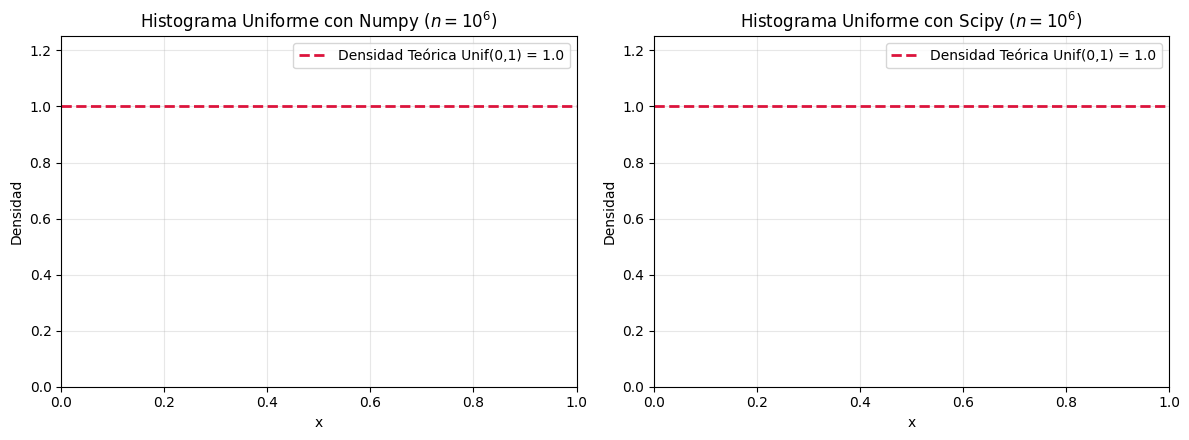

In [3]:
#2

n_muestras = 10**6
librerias = ["Numpy", "Scipy"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, lib in zip(axes, librerias):
  datos = uniforme(n_muestras, lib)
  sns.histplot(
    datos,
    bins=40,
    stat="density",
    ax=ax,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.8,
    )
  ax.axhline(
    1.0,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Densidad Teórica Unif(0,1) = 1.0",
    )
  ax.set_title(f"Histograma Uniforme con {lib} ($n=10^6$)")
  ax.set_xlabel("x")
  ax.set_ylabel("Densidad")
  ax.set_ylim(0, 1.25)
  ax.legend(loc="upper right")
  ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

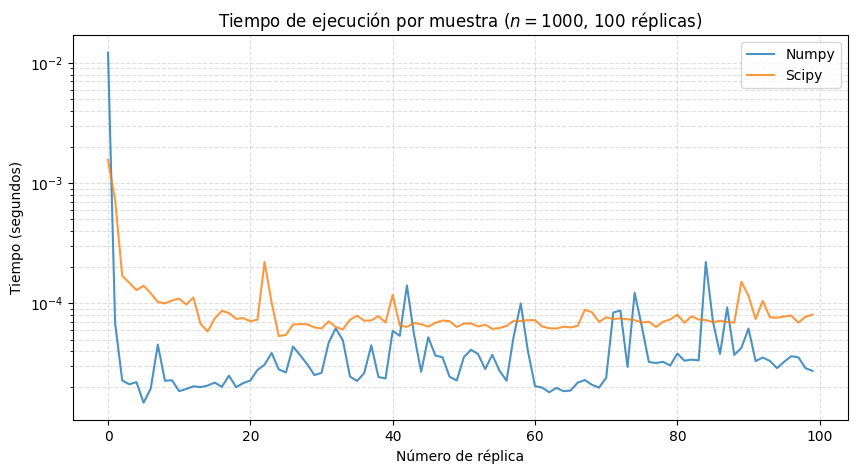

ESTADÍSTICAS DE TIEMPO DE EJECUCIÓN POR MUESTRA (n=1000)
Librería     | Media Tiempo (s)     | Varianza Tiempo (s²)
-----------------------------------------------------------------
Numpy        | 1.59388999e-04       | 1.46618084e-06      
Scipy        | 1.01122001e-04       | 2.64618748e-08      


In [4]:
#3

num_replicas = 100
n_tamano = 1000
metodos = ["Numpy", "Scipy"]

tiempos_dict = {m: [] for m in metodos}

for m in metodos:
  for _ in range(num_replicas):
    t0 = time.perf_counter()
    if m.lower() == "numpy":
      _ = np.random.uniform(0.0, 1.0, size=n_tamano)
    elif m.lower() == "scipy":
      _ = sp.stats.uniform.rvs(loc=0.0, scale=1.0, size=n_tamano)
    t1 = time.perf_counter()
    tiempos_dict[m].append(t1 - t0)

# Gráfico de tiempo de ejecución
plt.figure(figsize=(10, 5))
for m in metodos:
  plt.plot(tiempos_dict[m], label=f"{m}", alpha=0.8, linewidth=1.5)

plt.title("Tiempo de ejecución por muestra ($n=1000$, 100 réplicas)")
plt.xlabel("Número de réplica")
plt.ylabel("Tiempo (segundos)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.show()

# Resumen estadístico
print("=" * 65)
print("ESTADÍSTICAS DE TIEMPO DE EJECUCIÓN POR MUESTRA (n=1000)")
print("=" * 65)
print(
    f"{'Librería':<12} | {'Media Tiempo (s)':<20} | {'Varianza Tiempo (s²)':<20}"
)
print("-" * 65)
for m in metodos:
  media_t = np.mean(tiempos_dict[m])
  var_t = np.var(tiempos_dict[m], ddof=1)
  print(f"{m:<12} | {media_t:<20.8e} | {var_t:<20.8e}")
print("=" * 65)

In [5]:
#6

p_target = 1.0 - np.exp(-1.0)  # p = 1 - e^(-1) => 1 - p = e^(-1) => ln(1-p) = -1
esperanza_teorica = (1.0 - p_target) / p_target  # e^(-1)/(1 - e^(-1)) = 1/(e - 1) ≈ 0.5819767

np.random.seed(42)

# 1. 1000 Variables Independientes
U_ind = np.random.uniform(0.0, 1.0, size=1000)
X_ind = np.floor(-np.log(U_ind))
mu_ind = np.mean(X_ind)
var_ind = np.var(X_ind, ddof=1) / 1000

# 2. 1000 Variables Antitéticas (500 pares acoplados)
U_half = np.random.uniform(0.0, 1.0, size=500)
X_ant1 = np.floor(-np.log(U_half))
X_ant2 = np.floor(-np.log(1.0 - U_half))
X_ant = np.concatenate([X_ant1, X_ant2])
mu_ant = np.mean(X_ant)
cov_ant = np.cov(X_ant1, X_ant2)[0, 1]
var_ant = (np.var(X_ant1, ddof=1) + np.var(X_ant2, ddof=1) + 2 * cov_ant) / (
    4 * 500
)

# 3. Muestreo Estratificado (4 estratos, 250 muestras por estrato)
k_estratos = 4
N_estrato = 250
w_i = 1 / k_estratos
mu_estrat_sum = 0
var_estrat_sum = 0

for i in range(k_estratos):
  a, b = i / k_estratos, (i + 1) / k_estratos
  U_estrato = np.random.uniform(a, b, size=N_estrato)
  X_estrato = np.floor(-np.log(U_estrato))
  mu_i = np.mean(X_estrato)
  var_i = np.var(X_estrato, ddof=1)

  mu_estrat_sum += w_i * mu_i
  var_estrat_sum += (w_i**2) * (var_i / N_estrato)

mu_est = mu_estrat_sum
var_est = var_estrat_sum

print("=" * 72)
print(
    f"ESTIMACIÓN DE E[X] PARA Geom(1 - e⁻¹) | Valor Teórico:"
    f" {esperanza_teorica:.7f}"
)
print("=" * 72)
print(f"{'Método':<32} | {'Estimación μ̂':<15} | {'Varianza Estimador':<18}")
print("-" * 72)
print(f"{'1. Independiente (N=1000)':<32} | {mu_ind:<15.6f} | {var_ind:<18.2e}")
print(f"{'2. Antitético (500 pares)':<32} | {mu_ant:<15.6f} | {var_ant:<18.2e}")
print(f"{'3. Estratificado (4 estratos)':<32} | {mu_est:<15.6f} | {var_est:<18.2e}")
print("=" * 72)

ESTIMACIÓN DE E[X] PARA Geom(1 - e⁻¹) | Valor Teórico: 0.5819767
Método                           | Estimación μ̂   | Varianza Estimador
------------------------------------------------------------------------
1. Independiente (N=1000)        | 0.607000        | 8.77e-04          
2. Antitético (500 pares)        | 0.625000        | 6.03e-04          
3. Estratificado (4 estratos)    | 0.584000        | 3.19e-04          
